# 02 — Data Preparation

This notebook prepares the eligible OSMI 2016 respondent cohort for the four clustering methods specified in Notebook 01. The population, 15-feature scope and three-domain structure are fixed by that analysis.

| Clustering method | Prepared input |
|---|---|
| K-Modes | Original categorical responses |
| MCA + K-Means | Complete binary indicator matrix; MCA fitted in Notebook 03 |
| Agglomerative hierarchical | Domain-balanced Gower dissimilarity |
| HDBSCAN | The same domain-balanced Gower dissimilarity |

The selected feature set contains 14 nominal variables and one ordinal variable (`mh_medical_leave_ease`). Its five substantive responses are ordered; `I don't know` is treated as a separate nominal response. Demographic and contextual variables are excluded from all clustering representations.

No clustering model is fitted in this notebook.

## 1. Reproducibility and source contract

The source is the renamed interim dataset exported by Notebook 01. The cohort is reconstructed from its documented eligibility rule. Unexpected source dimensions or cohort size stop preparation rather than silently changing the analytical population.

In [2]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

RANDOM_STATE = 42
EXPECTED_SOURCE_ROWS = 1433
EXPECTED_COHORT_SIZE = 1131

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

ROOT = Path.cwd().resolve().parent if Path.cwd().resolve().name == "notebooks" else Path.cwd().resolve()
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures" / "data_preparation"

INPUT_FILE = INTERIM_DIR / "osmi_2016_renamed_interim.csv"
for directory in (PROCESSED_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"Notebook 01 interim export not found: {INPUT_FILE}")

df = pd.read_csv(INPUT_FILE)
if len(df) != EXPECTED_SOURCE_ROWS:
    raise AssertionError(f"Expected {EXPECTED_SOURCE_ROWS} source rows; found {len(df)}.")

if "source_row_position" in df.columns:
    raise ValueError("Unexpected source_row_position column; check the Notebook 01 export.")

df.insert(0, "source_row_position", np.arange(len(df), dtype=np.int64))
required = {"self_employed", "tech_company", "tech_role", "gender"}
missing = sorted(required.difference(df.columns))
if missing:
    raise KeyError(f"Required columns absent: {missing}")

display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "distinct": df.nunique(dropna=True),
}))

,dtype,missing,distinct
source_row_position,int64,0,1433
self_employed,int64,0,2
company_size,str,287,6
tech_company,float64,287,2
tech_role,float64,1170,2
...,...,...,...
us_state_live,str,593,47
country_work,str,0,53
us_state_work,str,582,48
work_position,str,0,264


## 2. Reconstruct the eligible respondent cohort

Eligibility is defined as non-self-employed respondents who either work for a technology company or hold a technology-related role:

$$
Eligible_i = (self\_employed_i=0) \land
[(tech\_company_i=1) \lor (tech\_role_i=1)]
$$

Missing cohort-defining values do not satisfy an affirmative condition.

,population,n
0,Source respondents,1433
1,Eligible respondents,1131


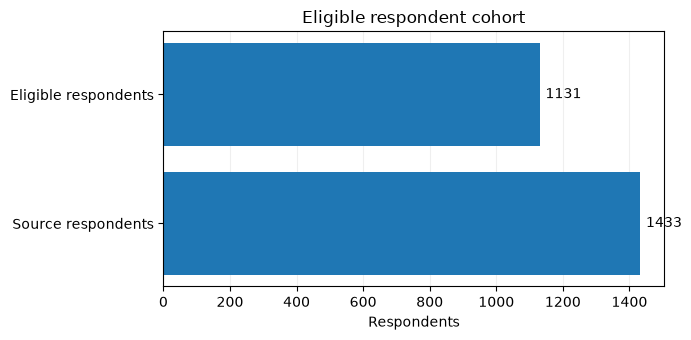

In [3]:
cohort_mask = (
    df["self_employed"].eq(0)
    & (df["tech_company"].eq(1) | df["tech_role"].eq(1))
)
cohort = df.loc[cohort_mask].copy().reset_index(drop=True)

cohort_audit = pd.DataFrame({
    "population": ["Source respondents", "Eligible respondents"],
    "n": [len(df), len(cohort)],
})
display(cohort_audit)

if len(cohort) != EXPECTED_COHORT_SIZE:
    raise AssertionError(
        f"Expected cohort size {EXPECTED_COHORT_SIZE}; observed {len(cohort)}. "
        "Reconcile the input and eligibility fields with Notebook 01 before proceeding."
    )

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(cohort_audit["population"], cohort_audit["n"])
ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_xlabel("Respondents")
ax.set_title("Eligible respondent cohort")
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cohort_selection.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Normalise text formatting

Whitespace is standardised without merging distinct response meanings. Empty strings become missing values. Source data remain available in `df`; `df_clean` contains the formatting-normalised copy.

In [4]:
def clean_text_value(value):
    if not isinstance(value, str):
        return value
    
    value = value.replace("\u00a0", " ")
    value = re.sub(r"[\t\r\n]+", " ", value)
    value = re.sub(r"\s+", " ", value).strip()
    
    return pd.NA if value == "" else value


def clean_text_columns(data):
    result = data.copy()
    for column in result.select_dtypes(include=["object", "string"]).columns:
        result[column] = result[column].map(clean_text_value)
    return result


df_clean = clean_text_columns(df)
cohort_clean = df_clean.loc[cohort_mask].copy().reset_index(drop=True)

assert df_clean.shape == df.shape
assert len(cohort_clean) == EXPECTED_COHORT_SIZE
assert cohort_clean["source_row_position"].is_unique

## 4. Descriptive gender harmonisation

Gender is retained for descriptive profiling only and is not a clustering feature. The original response remains unchanged. The harmonised category is deliberately coarse and must not be interpreted as a comprehensive representation of gender identity. Unmatched responses are grouped as `Other`; missing values remain missing.

,respondents
gender_profile,
Male,843
Female,264
Other,21
Missing,3


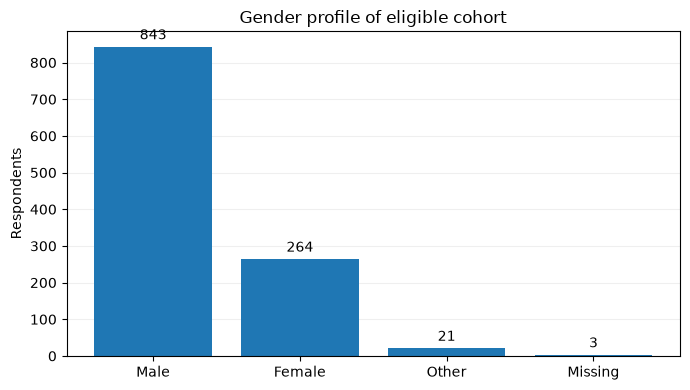

In [5]:
def gender_key(value):
    if pd.isna(value):
        return None
    value = clean_text_value(value)
    return None if pd.isna(value) else str(value).casefold()


male_values = {
    "male",
    "Male",
    "M",
    "m",
    "man",
    "Cis male",
    "Male.",
    "male 9:1 female, roughly",
    "Male (cis)",
    "Man",
    "Sex is male",
    "cis male",
    "Malr",
    "Dude",
    "mail",
    "M|",
    "Male/genderqueer",
    "male ",
    "Cis Male",
    "cisdude",
    "cis man",
    "MALE",
    "Male ",
    "Male (trans, FtM)",
    "I'm a man why didn't you make this a drop down question. You should of asked sex? And I would of answered yes please. Seriously how much text can this take? "
}
female_values = {
    "Female",
    "female",
    "female ",
    "F",
    "Woman",
    "fm",
    "f",
    "Cis female ",
    "Transitioned, M2F",
    " Female",
    "Cis-woman",
    "AFAB",
    "Genderfluid (born female)",
    "Female ",
    "woman",
    "female/woman",
    "Cisgender Female",
    "fem",
    "female-bodied; no feelings about gender",
    "Female (props for making this a freeform field, though)", 
    "I identify as female.",
    "Female assigned at birth ",
    "Female or Multi-Gender Femme",
    "mtf",
    "Transgender woman"
}

male_keys = {gender_key(x) for x in male_values}
female_keys = {gender_key(x) for x in female_values}

if male_keys.intersection(female_keys):
    raise AssertionError("Gender mapping sets overlap.")


def harmonise_gender(value):
    key = gender_key(value)
    if key is None:
        return pd.NA
    if key in male_keys:
        return "Male"
    if key in female_keys:
        return "Female"
    return "Other"


df_clean["gender_profile"] = df_clean["gender"].map(harmonise_gender).astype("string")
cohort_clean = df_clean.loc[cohort_mask].copy().reset_index(drop=True)

gender_counts = cohort_clean["gender_profile"].fillna("Missing").value_counts()
display(gender_counts.rename("respondents").to_frame())

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(gender_counts.index.astype(str), gender_counts.values)
ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_title("Gender profile of eligible cohort")
ax.set_ylabel("Respondents")
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gender_profile.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Define the primary feature set

The following features and domain assignments are fixed by Notebook 01. The feature set is not reselected using the descriptive results in this notebook.

In [6]:
FEATURES_BY_DOMAIN = {
    "employer_support": [
        "mh_benefits",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_vs_ph_seriousness",
    ],
    "psychological_safety": [
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "observed_mh_consequences",
    ],
    "disclosure_career_climate": [
        "interview_ph_reveal",
        "interview_mh_reveal",
        "mh_hurt_career",
        "coworker_negative_view",
    ],
}

PRIMARY_FEATURES = [f for group in FEATURES_BY_DOMAIN.values() for f in group]
FEATURE_DOMAIN = {f: domain for domain, group in FEATURES_BY_DOMAIN.items() for f in group}

ORDINAL_FEATURES = {
    "mh_medical_leave_ease": {
        "Very difficult": 1,
        "Somewhat difficult": 2,
        "Neither easy nor difficult": 3,
        "Somewhat easy": 4,
        "Very easy": 5,
    }
}

UNKNOWN_ORDINAL_RESPONSES = {"mh_medical_leave_ease": "I don't know"}
LEAVE_FEATURE = "mh_medical_leave_ease"

assert len(PRIMARY_FEATURES) == 15
assert len(set(PRIMARY_FEATURES)) == 15
missing_features = sorted(set(PRIMARY_FEATURES).difference(cohort_clean.columns))
if missing_features:
    raise KeyError(f"Selected features absent from data: {missing_features}")

feature_metadata = pd.DataFrame([
    {
        "feature": feature,
        "domain": FEATURE_DOMAIN[feature],
        "measurement_type": (
            "ordinal_with_nominal_unknown" if feature in ORDINAL_FEATURES else "nominal"
        ),
        "gower_treatment": (
            "normalised_ordinal_distance; unknown nominal"
            if feature in ORDINAL_FEATURES else "nominal_match_mismatch"
        ),
    }
    for feature in PRIMARY_FEATURES
])

display(feature_metadata)

,feature,domain,measurement_type,gower_treatment
0,mh_benefits,employer_support,nominal,nominal_match_mismatch
1,mh_formal_discussion,employer_support,nominal,nominal_match_mismatch
2,mh_resources_offered,employer_support,nominal,nominal_match_mismatch
3,mh_anonymity_protected,employer_support,nominal,nominal_match_mismatch
4,mh_medical_leave_ease,employer_support,ordinal_with_nominal_unknown,normalised_ordinal_distance; unknown nominal
5,mh_vs_ph_seriousness,employer_support,nominal,nominal_match_mismatch
6,mh_discussion_consequences,psychological_safety,nominal,nominal_match_mismatch
7,ph_discussion_consequences,psychological_safety,nominal,nominal_match_mismatch
8,mh_comfort_coworkers,psychological_safety,nominal,nominal_match_mismatch
9,mh_comfort_supervisor,psychological_safety,nominal,nominal_match_mismatch


## 6. Missingness and response-category audit

Notebook 01 establishes that the selected features are complete in the eligible cohort. No imputation is performed. Unexpected missingness is a data-contract failure and requires investigation rather than silent imputation or row deletion.

In [7]:
X_original = cohort_clean.loc[:, PRIMARY_FEATURES].copy()

missing_audit = pd.DataFrame({
    "feature": PRIMARY_FEATURES,
    "missing_count": X_original.isna().sum().to_numpy(),
    "missing_pct": (100 * X_original.isna().mean()).round(2).to_numpy(),
    "observed_categories": X_original.nunique(dropna=True).to_numpy(),
})
display(missing_audit)

if X_original.isna().any().any():
    raise ValueError("Missing values in selected features; investigate before modelling.")

response_audit = (
    X_original.melt(var_name="feature", value_name="response")
    .groupby(["feature", "response"], dropna=False)
    .size().rename("respondents").reset_index()
)
response_audit["percentage"] = (
    100 * response_audit["respondents"] / len(X_original)
).round(2)
display(response_audit.sort_values(["feature", "respondents"], ascending=[True, False]))

expected_leave_levels = [
    "Very difficult", "Somewhat difficult", "Neither easy nor difficult",
    "Somewhat easy", "Very easy", "I don't know",
]
observed_leave_levels = set(X_original[LEAVE_FEATURE].unique())
if observed_leave_levels != set(expected_leave_levels):
    raise AssertionError(f"Unexpected leave-ease levels: {observed_leave_levels}")

display(
    X_original[LEAVE_FEATURE].value_counts()
    .reindex(expected_leave_levels)
    .rename("respondents").to_frame()
)

,feature,missing_count,missing_pct,observed_categories
0,mh_benefits,0,0.0,4
1,mh_formal_discussion,0,0.0,3
2,mh_resources_offered,0,0.0,3
3,mh_anonymity_protected,0,0.0,3
4,mh_medical_leave_ease,0,0.0,6
5,mh_vs_ph_seriousness,0,0.0,3
6,mh_discussion_consequences,0,0.0,3
7,ph_discussion_consequences,0,0.0,3
8,mh_comfort_coworkers,0,0.0,3
9,mh_comfort_supervisor,0,0.0,3


,feature,response,respondents,percentage
0,coworker_negative_view,Maybe,456,40.32
1,coworker_negative_view,"No, I don't think they would",302,26.70
3,coworker_negative_view,"Yes, I think they would",301,26.61
2,coworker_negative_view,"No, they do not",44,3.89
4,coworker_negative_view,"Yes, they do",28,2.48
6,interview_mh_reveal,No,710,62.78
5,interview_mh_reveal,Maybe,331,29.27
7,interview_mh_reveal,Yes,90,7.96
8,interview_ph_reveal,Maybe,475,42.00
9,interview_ph_reveal,No,368,32.54


,respondents
mh_medical_leave_ease,
Very difficult,116
Somewhat difficult,192
Neither easy nor difficult,176
Somewhat easy,279
Very easy,219
I don't know,149


### Primary-feature response distributions

The panels show each variable's observed response frequencies. They are descriptive diagnostics; low-frequency responses are not automatically removed because category prevalence alone does not establish that a response is analytically irrelevant.

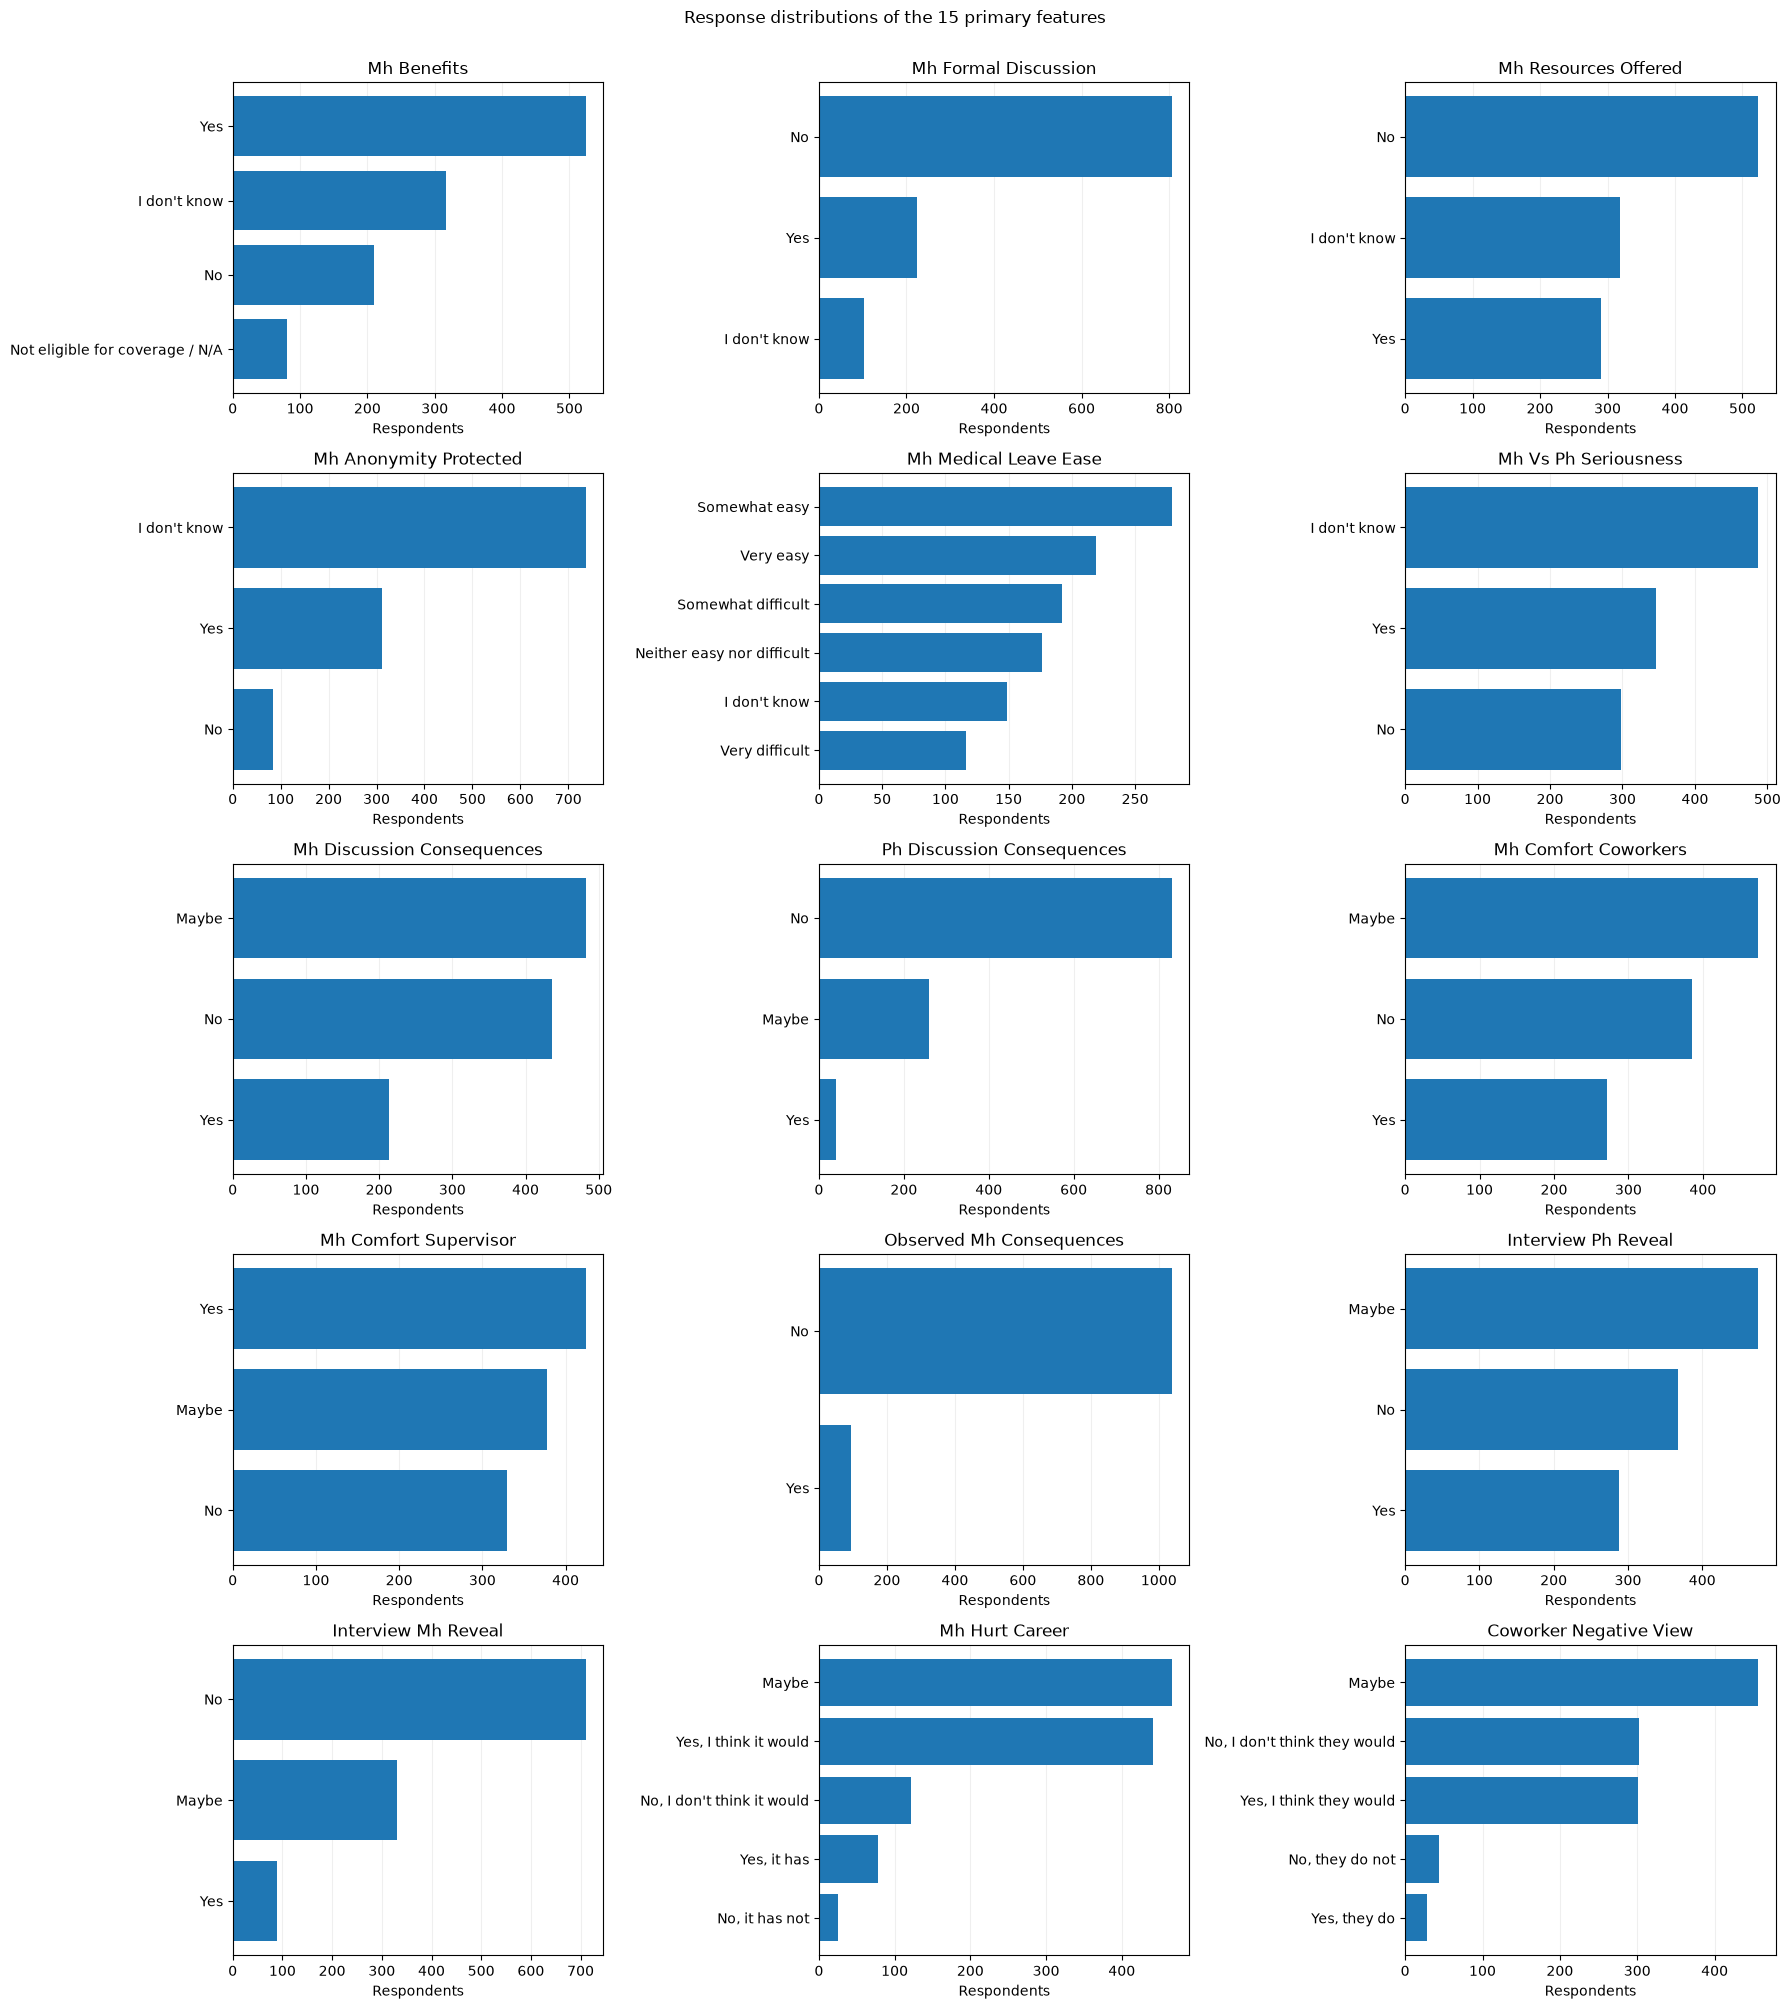

In [8]:
n_cols = 3
n_rows = int(np.ceil(len(PRIMARY_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = np.asarray(axes).ravel()

for i, feature in enumerate(PRIMARY_FEATURES):
    counts = X_original[feature].value_counts().sort_values()
    axes[i].barh(counts.index.astype(str), counts.values)
    axes[i].set_title(feature.replace("_", " ").title())
    axes[i].set_xlabel("Respondents")
    axes[i].grid(axis="x", alpha=.2)
    axes[i].set_axisbelow(True)

for ax in axes[len(PRIMARY_FEATURES):]:
    ax.set_visible(False)

fig.suptitle("Response distributions of the 15 primary features", y=1.002)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "primary_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 7. K-Modes representation

K-Modes operates directly on categorical response labels using matching dissimilarity. No ordinal rank conversion, integer encoding, scaling or one-hot encoding is applied to this representation.

In [9]:
X_kmodes = X_original.astype("string").reset_index(drop=True)
assert X_kmodes.shape == (EXPECTED_COHORT_SIZE, 15)
assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert not X_kmodes.isna().any().any()
display(X_kmodes.head())

,mh_benefits,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_vs_ph_seriousness,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,observed_mh_consequences,interview_ph_reveal,interview_mh_reveal,mh_hurt_career,coworker_negative_view
0,Not eligible for coverage / N/A,No,No,I don't know,Very easy,I don't know,No,No,Maybe,Yes,No,Maybe,Maybe,Maybe,"No, I don't think they would"
1,No,Yes,Yes,Yes,Somewhat easy,Yes,No,No,Maybe,Yes,No,Maybe,No,"No, I don't think it would","No, I don't think they would"
2,No,No,No,I don't know,Neither easy nor difficult,I don't know,Maybe,No,Maybe,Maybe,No,Yes,Yes,Maybe,Maybe
3,Yes,No,No,No,Neither easy nor difficult,No,Yes,Maybe,Maybe,No,No,Maybe,No,"Yes, I think it would",Maybe
4,Yes,No,Yes,Yes,Somewhat easy,No,Yes,Yes,Maybe,Yes,Yes,Yes,Maybe,"Yes, I think it would",Maybe


## 8. MCA indicator representation

Each observed category is represented by a binary indicator column. Exactly one indicator must be active for each original feature and respondent. MCA fitting and dimensionality decisions are reserved for Notebook 03.

In [11]:
X_mca_indicator = pd.get_dummies(
    X_kmodes,
    columns=PRIMARY_FEATURES,
    prefix=PRIMARY_FEATURES,
    prefix_sep="=",
    dtype=np.uint8,
).reset_index(drop=True)

indicator_columns_by_feature = {
    feature: [c for c in X_mca_indicator.columns if c.startswith(f"{feature}=")]
    for feature in PRIMARY_FEATURES
}

for feature, columns in indicator_columns_by_feature.items():
    if len(columns) < 2:
        raise AssertionError(f"Fewer than two categories observed for {feature}.")
    if not X_mca_indicator[columns].sum(axis=1).eq(1).all():
        raise AssertionError(f"One-hot encoding constraint failed for {feature}.")

assert set(np.unique(X_mca_indicator.to_numpy())).issubset({0, 1})
print("MCA indicator matrix:", X_mca_indicator.shape)
display(X_mca_indicator.head())

MCA indicator matrix: (1131, 52)


,mh_benefits=I don't know,mh_benefits=No,mh_benefits=Not eligible for coverage / N/A,mh_benefits=Yes,mh_formal_discussion=I don't know,mh_formal_discussion=No,mh_formal_discussion=Yes,mh_resources_offered=I don't know,mh_resources_offered=No,mh_resources_offered=Yes,mh_anonymity_protected=I don't know,mh_anonymity_protected=No,mh_anonymity_protected=Yes,mh_medical_leave_ease=I don't know,mh_medical_leave_ease=Neither easy nor difficult,mh_medical_leave_ease=Somewhat difficult,mh_medical_leave_ease=Somewhat easy,mh_medical_leave_ease=Very difficult,mh_medical_leave_ease=Very easy,mh_vs_ph_seriousness=I don't know,mh_vs_ph_seriousness=No,mh_vs_ph_seriousness=Yes,mh_discussion_consequences=Maybe,mh_discussion_consequences=No,mh_discussion_consequences=Yes,ph_discussion_consequences=Maybe,ph_discussion_consequences=No,ph_discussion_consequences=Yes,mh_comfort_coworkers=Maybe,mh_comfort_coworkers=No,mh_comfort_coworkers=Yes,mh_comfort_supervisor=Maybe,mh_comfort_supervisor=No,mh_comfort_supervisor=Yes,observed_mh_consequences=No,observed_mh_consequences=Yes,interview_ph_reveal=Maybe,interview_ph_reveal=No,interview_ph_reveal=Yes,interview_mh_reveal=Maybe,interview_mh_reveal=No,interview_mh_reveal=Yes,mh_hurt_career=Maybe,"mh_hurt_career=No, I don't think it would","mh_hurt_career=No, it has not","mh_hurt_career=Yes, I think it would","mh_hurt_career=Yes, it has",coworker_negative_view=Maybe,"coworker_negative_view=No, I don't think they would","coworker_negative_view=No, they do not","coworker_negative_view=Yes, I think they would","coworker_negative_view=Yes, they do"
0,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0
1,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0
2,0,1,0,0,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0
3,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0
4,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,0,1,0,0,0,0


## 9. Domain-balanced Gower dissimilarity

Nominal variables use match/mismatch dissimilarity. The five substantive responses for `mh_medical_leave_ease` use the normalised absolute rank difference. The `I don't know` response remains nominal: unknown–unknown has distance 0; unknown–substantive has distance 1.

First, feature dissimilarities are averaged within each domain. The three domain averages are then weighted equally:

$$
D_{il}=\frac{1}{3}\sum_{g=1}^{3}
\left(\frac{1}{p_g}\sum_{j\in g}d_{ilj}\right)
$$

This gives each domain equal total influence rather than allowing the domain with the most variables to dominate by feature count.

In [12]:
X_gower_typed = X_original.astype("string").reset_index(drop=True)


def nominal_dissimilarity(values):
    values = np.asarray(values, dtype=object)
    return (values[:, None] != values[None, :]).astype(np.float32)


def ordinal_unknown_dissimilarity(values, rank_mapping, unknown_label):
    values = np.asarray(values, dtype=object)
    n = len(values)
    unknown = values == unknown_label
    ranks = np.full(n, np.nan, dtype=np.float32)

    for category, rank in rank_mapping.items():
        ranks[values == category] = rank

    invalid = ~unknown & np.isnan(ranks)
    if invalid.any():
        raise ValueError(f"Undeclared ordinal responses: {pd.unique(values[invalid])}")

    result = np.empty((n, n), dtype=np.float32)
    both_substantive = (~unknown[:, None]) & (~unknown[None, :])
    both_unknown = unknown[:, None] & unknown[None, :]
    one_unknown = unknown[:, None] ^ unknown[None, :]

    rank_dist = np.abs(ranks[:, None] - ranks[None, :]) / (len(rank_mapping) - 1)
    result[both_substantive] = rank_dist[both_substantive]
    result[both_unknown] = 0.0
    result[one_unknown] = 1.0
    return result


def build_domain_balanced_dissimilarity(data, domains, ordinal_specs, unknown_specs):
    domain_matrices = {}
    for domain, features in domains.items():
        matrices = []
        for feature in features:
            values = data[feature].to_numpy(dtype=object)
            if feature in ordinal_specs:
                matrix = ordinal_unknown_dissimilarity(
                    values, ordinal_specs[feature], unknown_specs[feature]
                )
            else:
                matrix = nominal_dissimilarity(values)
            matrices.append(matrix)
        domain_matrices[domain] = np.mean(np.stack(matrices), axis=0, dtype=np.float32)

    result = np.mean(np.stack(list(domain_matrices.values())), axis=0, dtype=np.float32)
    result = (result + result.T) / 2
    np.fill_diagonal(result, 0)
    return result, domain_matrices


D_gower, domain_dissimilarities = build_domain_balanced_dissimilarity(
    X_gower_typed,
    FEATURES_BY_DOMAIN,
    ORDINAL_FEATURES,
    UNKNOWN_ORDINAL_RESPONSES
)

### Dissimilarity validation and visual diagnostic

The full matrix is used for modelling. The heatmap displays a reproducible sample to keep the visualisation interpretable.

{'shape': (1131, 1131), 'dtype': 'float32', 'minimum': 0.0, 'maximum': 1.0, 'mean': 0.5665361285209656, 'memory_mib': 4.88}


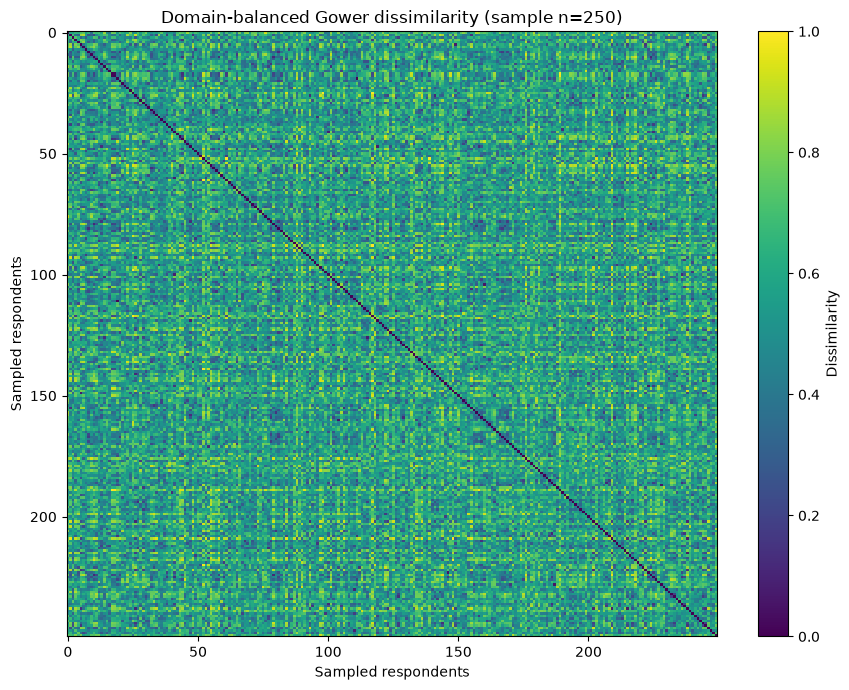

In [13]:
n = len(X_gower_typed)
assert D_gower.shape == (n, n)
assert np.isfinite(D_gower).all()
assert np.allclose(D_gower, D_gower.T, atol=1e-7)
assert np.allclose(np.diag(D_gower), 0, atol=1e-7)
assert D_gower.min() >= -1e-7 and D_gower.max() <= 1 + 1e-7

print({
    "shape": D_gower.shape,
    "dtype": str(D_gower.dtype),
    "minimum": float(D_gower.min()),
    "maximum": float(D_gower.max()),
    "mean": float(D_gower.mean()),
    "memory_mib": round(D_gower.nbytes / 1024**2, 2),
})

rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(n, size=min(250, n), replace=False))
D_sample = D_gower[np.ix_(sample_idx, sample_idx)]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(D_sample, vmin=0, vmax=1, interpolation="nearest", aspect="auto")
ax.set_title(f"Domain-balanced Gower dissimilarity (sample n={len(sample_idx)})")
ax.set_xlabel("Sampled respondents")
ax.set_ylabel("Sampled respondents")
fig.colorbar(im, ax=ax, label="Dissimilarity")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gower_dissimilarity_sample.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Pairwise feature association audit

Bias-corrected Cramér's V summarises pairwise categorical association. It is descriptive only. It is not used for automatic feature removal and cannot serve as independent validation of clusters subsequently constructed from these same features. All Notebook 01 features are retained.

,feature_a,feature_b,cramers_v_bias_corrected
0,mh_comfort_coworkers,mh_comfort_supervisor,0.476085
1,mh_hurt_career,coworker_negative_view,0.429113
2,interview_ph_reveal,interview_mh_reveal,0.424631
3,mh_discussion_consequences,mh_comfort_supervisor,0.423584
4,mh_medical_leave_ease,mh_discussion_consequences,0.421017
5,mh_discussion_consequences,ph_discussion_consequences,0.398345
6,mh_discussion_consequences,coworker_negative_view,0.386608
7,mh_formal_discussion,mh_resources_offered,0.375119
8,mh_vs_ph_seriousness,mh_discussion_consequences,0.371310
9,mh_discussion_consequences,mh_hurt_career,0.366348


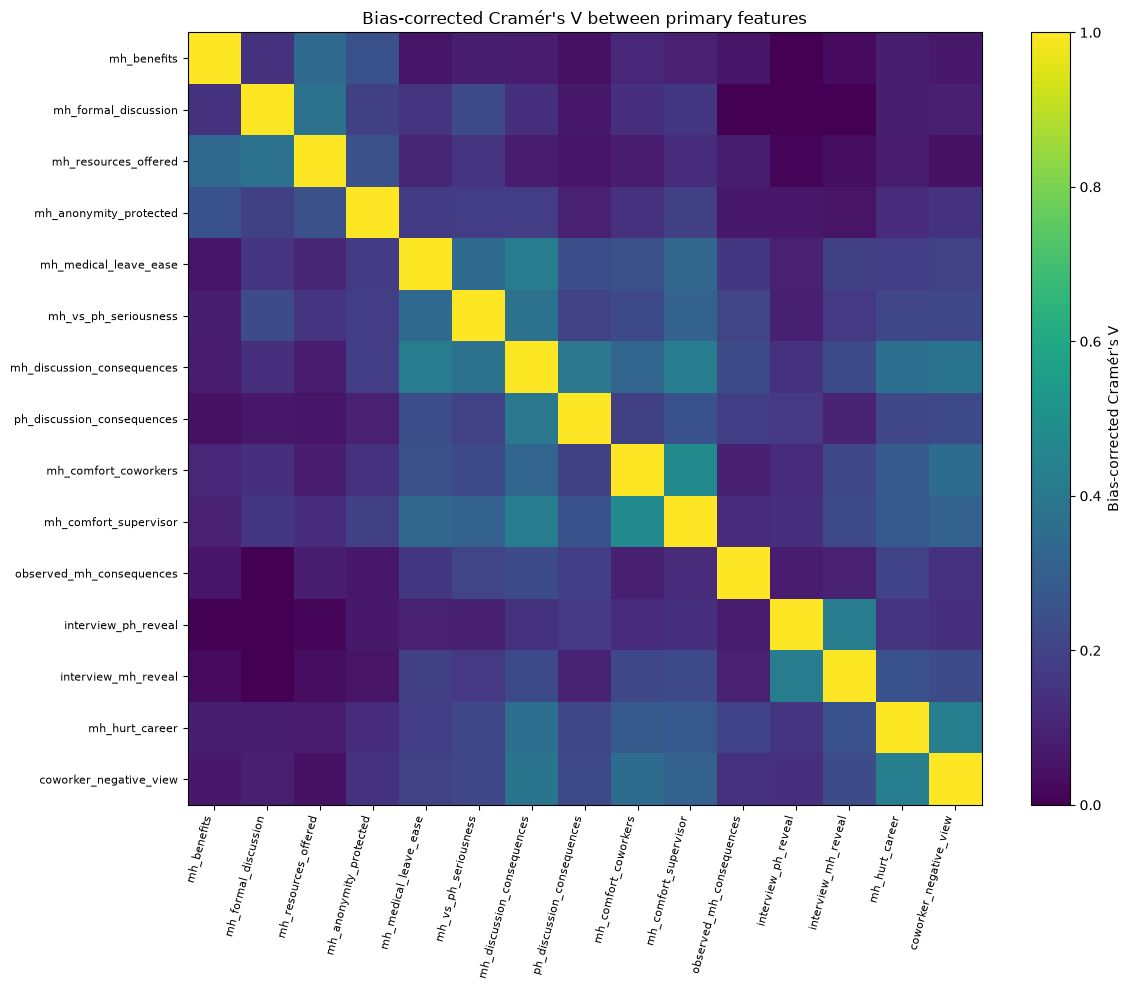

In [14]:
def cramers_v_bias_corrected(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    n = len(pair)
    if n <= 1:
        return np.nan
    table = pd.crosstab(pair["x"], pair["y"])
    r, k = table.shape
    if r < 2 or k < 2:
        return np.nan

    chi2 = chi2_contingency(table.to_numpy(), correction=False)[0]
    phi2 = chi2 / n
    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denominator = min(r_corr - 1, k_corr - 1)
    return np.nan if denominator <= 0 else float(np.sqrt(phi2_corr / denominator))


p = len(PRIMARY_FEATURES)
cramers_v_matrix = pd.DataFrame(np.eye(p), index=PRIMARY_FEATURES, columns=PRIMARY_FEATURES)
association_rows = []

for i, feature_a in enumerate(PRIMARY_FEATURES):
    for feature_b in PRIMARY_FEATURES[i + 1:]:
        value = cramers_v_bias_corrected(X_original[feature_a], X_original[feature_b])
        cramers_v_matrix.loc[feature_a, feature_b] = value
        cramers_v_matrix.loc[feature_b, feature_a] = value
        association_rows.append({
            "feature_a": feature_a,
            "feature_b": feature_b,
            "cramers_v_bias_corrected": value,
        })

cramers_v_pairs = pd.DataFrame(association_rows).sort_values(
    "cramers_v_bias_corrected", ascending=False, na_position="last"
).reset_index(drop=True)
assert len(cramers_v_pairs) == 105
display(cramers_v_pairs.head(15))

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cramers_v_matrix.to_numpy(dtype=float), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(p), PRIMARY_FEATURES, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(p), PRIMARY_FEATURES, fontsize=8)
ax.set_title("Bias-corrected Cramér's V between primary features")
fig.colorbar(im, ax=ax, label="Bias-corrected Cramér's V")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cramers_v_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Respondent row lineage

`model_row_index` identifies the row position in every modelling representation. `source_row_position` links it to the original interim file. These identifiers are retained for auditability and must never be used as clustering features.

In [15]:
model_row_mapping = pd.DataFrame({
    "model_row_index": np.arange(len(cohort_clean), dtype=np.int64),
    "source_row_position": cohort_clean["source_row_position"].to_numpy(dtype=np.int64),
})

assert model_row_mapping["model_row_index"].is_unique
assert model_row_mapping["source_row_position"].is_unique

## 12. Final quality assurance

The checks enforce cohort size, feature order, completeness, one-hot validity, Gower matrix properties and respondent alignment. Contextual and demographic variables are excluded from the prepared feature matrices.

In [16]:
assert len(cohort_clean) == EXPECTED_COHORT_SIZE
assert len(PRIMARY_FEATURES) == 15
assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert list(X_gower_typed.columns) == PRIMARY_FEATURES
assert len(X_kmodes) == len(X_mca_indicator) == len(X_gower_typed) == len(model_row_mapping)
assert not X_kmodes.isna().any().any()
assert not X_mca_indicator.isna().any().any()
assert not X_gower_typed.isna().any().any()

for feature, columns in indicator_columns_by_feature.items():
    assert X_mca_indicator[columns].sum(axis=1).eq(1).all()

assert D_gower.shape == (EXPECTED_COHORT_SIZE, EXPECTED_COHORT_SIZE)
assert np.isfinite(D_gower).all()
assert np.allclose(D_gower, D_gower.T, atol=1e-7)
assert np.allclose(np.diag(D_gower), 0, atol=1e-7)
assert D_gower.min() >= -1e-7 and D_gower.max() <= 1 + 1e-7

excluded = {
    "gender",
    "gender_profile",
    "age",
    "country",
    "state",
    "company_size",
    "work_remote",
    "self_employed",
    "tech_company",
    "tech_role",
    "source_row_position",
}

for matrix in (X_kmodes, X_mca_indicator, X_gower_typed):
    assert not excluded.intersection(matrix.columns)

assert np.array_equal(
    model_row_mapping["source_row_position"].to_numpy(),
    cohort_clean["source_row_position"].to_numpy(),
)
print("Preparation quality assurance passed.")

Preparation quality assurance passed.


## 13. Export prepared artefacts

The export names below form the interface consumed by Notebook 03. The cleaned cohort supports traceability and descriptive profiling; only the algorithm-specific artefacts are model inputs.

In [17]:
OUTPUT_FILES = {
    "cleaned_respondents": PROCESSED_DIR / "osmi_2016_cleaned_respondents.csv",
    "primary_cohort": PROCESSED_DIR / "osmi_2016_primary_cohort.csv",
    "row_mapping": PROCESSED_DIR / "osmi_2016_model_row_mapping.csv",
    "kmodes_input": PROCESSED_DIR / "osmi_2016_kmodes_input.csv",
    "mca_indicator_matrix": PROCESSED_DIR / "osmi_2016_mca_indicator_matrix.csv",
    "gower_typed_input": PROCESSED_DIR / "osmi_2016_gower_typed_input.csv",
    "gower_dissimilarity": PROCESSED_DIR / "osmi_2016_gower_dissimilarity.npy",
    "feature_metadata": PROCESSED_DIR / "osmi_2016_feature_metadata.csv",
    "cramers_v_matrix": PROCESSED_DIR / "osmi_2016_cramers_v_matrix.csv",
    "cramers_v_pairs": PROCESSED_DIR / "osmi_2016_cramers_v_pairs.csv",
    "preparation_metadata": PROCESSED_DIR / "osmi_2016_preparation_metadata.json",
}

df_clean.to_csv(OUTPUT_FILES["cleaned_respondents"], index=False)
cohort_clean.to_csv(OUTPUT_FILES["primary_cohort"], index=False)
model_row_mapping.to_csv(OUTPUT_FILES["row_mapping"], index=False)
X_kmodes.to_csv(OUTPUT_FILES["kmodes_input"], index=False)
X_mca_indicator.to_csv(OUTPUT_FILES["mca_indicator_matrix"], index=False)
X_gower_typed.to_csv(OUTPUT_FILES["gower_typed_input"], index=False)
np.save(OUTPUT_FILES["gower_dissimilarity"], D_gower, allow_pickle=False)
feature_metadata.to_csv(OUTPUT_FILES["feature_metadata"], index=False)
cramers_v_matrix.to_csv(OUTPUT_FILES["cramers_v_matrix"])
cramers_v_pairs.to_csv(OUTPUT_FILES["cramers_v_pairs"], index=False)

### Preparation metadata

The metadata file records the exact feature schema, measurement treatment, distance definition, row count and model-input filenames for reproducible downstream loading.

In [18]:
preparation_metadata = {
    "project": "OSMI 2016 Mental Health in Technology-related Jobs",
    "notebook": "02_data_preparation",
    "random_state": int(RANDOM_STATE),
    "source_file": str(INPUT_FILE),
    "source_respondents": int(len(df_clean)),
    "eligible_cohort_size": int(len(cohort_clean)),
    "cohort_definition": "self_employed == 0 AND (tech_company == 1 OR tech_role == 1)",
    "primary_feature_count": int(len(PRIMARY_FEATURES)),
    "primary_features": list(PRIMARY_FEATURES),
    "feature_domains": {k: list(v) for k, v in FEATURES_BY_DOMAIN.items()},
    "feature_domain_weights": {k: 1.0 / len(FEATURES_BY_DOMAIN) for k in FEATURES_BY_DOMAIN},
    "feature_measurement_types": {
        f: ("ordinal_with_nominal_unknown" if f in ORDINAL_FEATURES else "nominal")
        for f in PRIMARY_FEATURES
    },
    "ordinal_feature": {
        "name": LEAVE_FEATURE,
        "ranks": ORDINAL_FEATURES[LEAVE_FEATURE],
        "unknown_response": UNKNOWN_ORDINAL_RESPONSES[LEAVE_FEATURE],
        "unknown_distance_policy": "unknown-unknown=0; unknown-substantive=1",
    },
    "missing_value_policy": "No imputation; unexpected primary-feature missingness stops preparation.",
    "gender_policy": "Descriptive profile only; excluded from all clustering representations.",
    "gower_method": {
        "nominal": "match=0; mismatch=1",
        "ordinal": "absolute substantive rank difference divided by 4",
        "domain_balancing": "average features within each domain, then equal average across domains",
        "shape": [int(x) for x in D_gower.shape],
        "dtype": str(D_gower.dtype),
        "minimum": float(D_gower.min()),
        "maximum": float(D_gower.max()),
    },
    "association_audit": {
        "method": "Bias-corrected Cramer's V",
        "pair_count": int(len(cramers_v_pairs)),
        "purpose": "Descriptive only; no feature removal or independent cluster validation.",
    },
    "algorithm_inputs": {
        "K-Modes": "osmi_2016_kmodes_input.csv",
        "MCA + K-Means": "osmi_2016_mca_indicator_matrix.csv",
        "Agglomerative": "osmi_2016_gower_dissimilarity.npy",
        "HDBSCAN": "osmi_2016_gower_dissimilarity.npy",
    },
    "row_mapping_file": "osmi_2016_model_row_mapping.csv",
    "model_fitting_performed": False,
    "mca_fitting_performed": False,
}

with OUTPUT_FILES["preparation_metadata"].open("w", encoding="utf-8") as f:
    json.dump(preparation_metadata, f, indent=2, ensure_ascii=False, allow_nan=False)

## 14. Export verification

The saved artefacts are reloaded and checked against the in-memory representations. Notebook 03 should use these files and preserve the supplied row order.

In [19]:
export_audit = pd.DataFrame([
    {
        "artefact": name,
        "filename": path.name,
        "exists": path.is_file(),
        "size_kb": round(path.stat().st_size / 1024, 2) if path.is_file() else 0,
    }
    for name, path in OUTPUT_FILES.items()
])

display(export_audit)

assert export_audit["exists"].all()
assert (export_audit["size_kb"] > 0).all()

kmodes_check = pd.read_csv(OUTPUT_FILES["kmodes_input"], dtype="string")
mca_check = pd.read_csv(OUTPUT_FILES["mca_indicator_matrix"])
gower_check = pd.read_csv(OUTPUT_FILES["gower_typed_input"], dtype="string")
mapping_check = pd.read_csv(OUTPUT_FILES["row_mapping"])
distance_check = np.load(OUTPUT_FILES["gower_dissimilarity"], allow_pickle=False)
with OUTPUT_FILES["preparation_metadata"].open(encoding="utf-8") as f:
    metadata_check = json.load(f)

assert kmodes_check.shape == (EXPECTED_COHORT_SIZE, 15)
assert list(kmodes_check.columns) == PRIMARY_FEATURES
assert mca_check.shape == X_mca_indicator.shape
assert gower_check.shape == (EXPECTED_COHORT_SIZE, 15)
assert len(mapping_check) == EXPECTED_COHORT_SIZE
assert np.allclose(distance_check, D_gower, atol=1e-7)
assert metadata_check["primary_features"] == PRIMARY_FEATURES
assert metadata_check["eligible_cohort_size"] == EXPECTED_COHORT_SIZE

print("All prepared artefacts were exported and reloaded successfully.")

,artefact,filename,exists,size_kb
0,cleaned_respondents,osmi_2016_cleaned_respondents.csv,True,1044.50
1,primary_cohort,osmi_2016_primary_cohort.csv,True,814.10
2,row_mapping,osmi_2016_model_row_mapping.csv,True,10.25
3,kmodes_input,osmi_2016_kmodes_input.csv,True,129.04
4,mca_indicator_matrix,osmi_2016_mca_indicator_matrix.csv,True,117.53
5,gower_typed_input,osmi_2016_gower_typed_input.csv,True,129.04
6,gower_dissimilarity,osmi_2016_gower_dissimilarity.npy,True,4996.85
7,feature_metadata,osmi_2016_feature_metadata.csv,True,1.17
8,cramers_v_matrix,osmi_2016_cramers_v_matrix.csv,True,4.62
9,cramers_v_pairs,osmi_2016_cramers_v_pairs.csv,True,6.48


All prepared artefacts were exported and reloaded successfully.


## 15. Modelling handoff

The prepared cohort contains **1,131 respondents** and the **15 workplace-climate features** specified in Notebook 01. The three feature domains have equal total weight in the Gower representation.

- **K-Modes:** categorical response labels without numeric encoding.
- **MCA + K-Means:** binary indicator matrix; MCA fitting and dimension selection occur in Notebook 03.
- **Agglomerative hierarchical clustering:** full domain-balanced Gower dissimilarity matrix.
- **HDBSCAN:** the same precomputed domain-balanced Gower dissimilarity matrix.

No selected-feature imputation, model fitting or cluster interpretation occurs here. `model_row_index` must be preserved when candidate labels are generated. The Cramér's V audit is descriptive and must not be presented as independent cluster validation.